# PCDE — Underwater Image Enhancement via Piecewise Color Correction and Dual Prior Optimized Contrast Enhancement





1. **Piecewise color correction (PCC)**
2. RGB → HSV; the **V channel** is split into a base and a detail layer by the **L1–L0 ADMM decomposition**
3. **Base-layer enhancement** + gamma, **detail-layer enhancement**
4. Reconstruction **V<sup>E</sup> = B<sup>E</sup> + 2·D<sup>E</sup>**, then HSV → RGB
5. Evaluation (AG, EI, UIQM, UCIQE)

**Parameters stated in the paper:** λ₁ = 0.25, λ₂ = 0.025, 20 ADMM iterations, block K = 20×20, δ = 2, θ = 0.65, σ = 0.88, reconstruction gain 2.





## Extension — three decomposition models,


| | name used below | objective (V = decomposition input S, B = base layer, D = V − B) | spatial prior | texture prior |
|---|---|---|---|---|
| **M1** | `M1 L1+L0` | ½‖V−B‖² + λ₁‖∇B‖₁ + λ₂‖∇(V−B)‖₀ | **L1** (componentwise soft threshold) | L0 |
| **M2** | `M2 L2g+L0` | ½‖V−B‖² + λ₁‖∇B‖₂ + λ₂‖∇(V−B)‖₀ | **global L2** (one Euclidean norm over *all* horizontal+vertical gradient entries → one common shrink factor) | L0 |
| **M3** | `M3 L2g` | ½‖V−B‖² + λ₁‖∇B‖₂ | **global L2** | none (D is just the residual V − B) |

What is **shared** by the three models (computed once): piecewise colour correction, RGB→HSV, the log-normalised decomposition input S, gradient operator / adjoint, the FFT solver, hard threshold, base-layer enhancement (Eq. 7 + gamma), detail-layer enhancement (Eq. 8), reconstruction (Eq. 9), metrics.

What **differs**: only the ADMM decomposition. Everything after it is run once per model and displayed in parallel.



In [ ]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import ndimage
from scipy.fft import fft2, ifft2
from IPython.display import display

np.set_printoptions(precision=6, suppress=True)

## 1. Configuration



In [ ]:
# ---------------------------------------------------------
# Input
# ---------------------------------------------------------
IMAGE_PATH = "/content/uww.jpg"

# ---------------------------------------------------------
# Parameters published in the paper
# ---------------------------------------------------------
LAMBDA1 = 0.25            # weight of the L1 spatial prior on the base layer, Eq. (5)
LAMBDA2 = 0.025           # weight of the L0 texture prior on the detail layer, Eq. (5)
ADMM_ITERATIONS = 20      # "20 iterations"

PCDE_BLOCK_SIZE = 20      # local block K = 20 x 20, Eq. (7)
PCDE_DELTA = 2.0          # delta, Eq. (7)
PCDE_THETA = 0.65         # gamma factor theta applied to the enhanced base layer
PCDE_SIGMA = 0.88         # detail stretching exponent sigma, Eq. (8)
PCDE_DETAIL_GAIN = 2.0    # the factor 2 in Eq. (9)

# ---------------------------------------------------------
# NOT specified by the PCDE paper -> taken from its source reference [35]
# ---------------------------------------------------------
USE_LOG_DOMAIN = True     # decompose nor(log(V + eps)) as in [35] Sec. 4 (False = plain V)
LOG_EPS = 1e-4            # the 0.0001 of [35]'s demo.m
ADMM_RHO0 = 1.0           # initial penalty (rho = eta in the PCDE notation)
ADMM_RHO_GROWTH = 2.0     # rho_{k+1} = growth * rho_k ; [35] text: 2, [35] code: 4

# ---------------------------------------------------------
# two extra decomposition models that are compared with the paper model M1
# ---------------------------------------------------------
MODEL_NAMES = ["M1 L1+L0", "M2 L2g+L0", "M3 L2g"]
MODEL_COLORS = ["#0072B2", "#D55E00", "#009E73"]

L2G_LAMBDA1 = LAMBDA1       # weight of the GLOBAL L2 spatial prior lambda1*||grad B||_2 (M2, M3)
L2G_LAMBDA2 = LAMBDA2       # weight of the L0 texture prior of M2 (same value as the paper)
L2G_INIT_A1_FROM_GRADIENT = True   # derivations: A1(0) = grad V ; False -> A1(0) = 0 as in the L1+L0 code

# optional residual-based stopping for M2 / M3
ADMM_TOL_PRIMAL = None
ADMM_TOL_DUAL = None

## 2. Load the input image

Image shape: (453, 678, 3) | dtype: uint8
Value range: 0 255


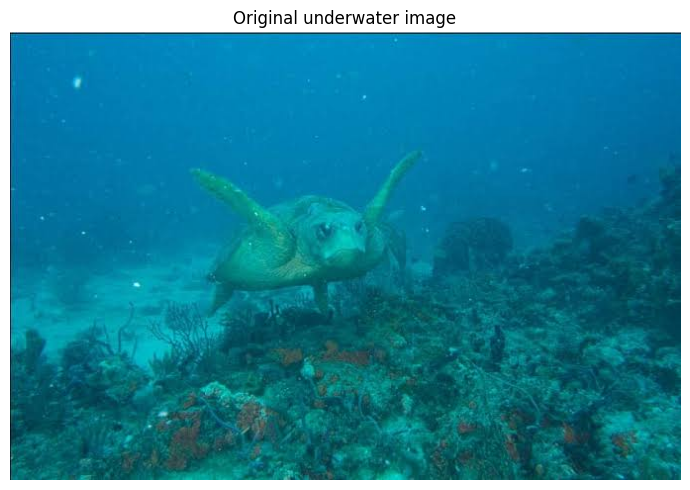

In [ ]:
image_bgr = cv2.imread(IMAGE_PATH)

if image_bgr is None:
    raise FileNotFoundError(
        f"Image not found: {IMAGE_PATH}. "
        "Upload the image to Colab or change IMAGE_PATH."
    )

image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)          # uint8, RGB

def to_uint8(x):
    return np.rint(np.clip(x, 0, 255)).astype(np.uint8)

print("Image shape:", image.shape, "| dtype:", image.dtype)
print("Value range:", int(image.min()), int(image.max()))

plt.figure(figsize=(8, 5))
plt.imshow(image)
plt.title("Original underwater image")
plt.axis("off")
plt.tight_layout()
plt.show()

## 3. Piecewise Color Correction (PCC) — Eq. (1)–(4)

* Eq. (1): channel means  Ī<sub>c</sub> = (1/HW) Σ I<sub>c</sub>(i, j)
* Eq. (2): reference mean  Ī<sub>Ref</sub> = max(Ī<sub>R</sub>, Ī<sub>G</sub>, Ī<sub>B</sub>)
* Eq. (3)/(4): each channel is split at Ī<sub>Ref</sub> into two pieces

  I<sub>CR</sub><sup>c</sup> = Ī<sub>Ref</sub> + α (I<sub>c</sub> − Ī<sub>c</sub>)  if Ī<sub>Ref</sub> < I<sub>c</sub>

  I<sub>CR</sub><sup>c</sup> = Ī<sub>Ref</sub> − β (Ī<sub>c</sub> − I<sub>c</sub>)  if Ī<sub>Ref</sub> ≥ I<sub>c</sub>

  with α = max<sub>c</sub> 255 / (I<sup>c</sup><sub>Max</sub> − I<sup>c</sup><sub>Min</sub>) and β = max<sub>c</sub> Ī<sub>c</sub> / 255 (both are single scalars shared by all channels).



Channel means (R, G, B): [  5.167507 114.885887 141.524292]
Reference mean         : 141.52429232842994
alpha                  : 1.6887417218543046
beta                   : 0.5549972248173723
Corrected channel means: [141.52451  145.759975 159.76345 ]


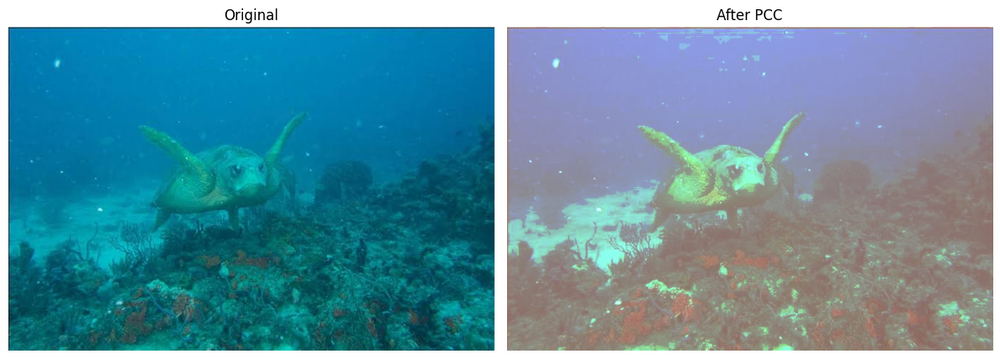

In [ ]:
def piecewise_color_correction(image_rgb):
    f = image_rgb.astype(np.float64)

    mean_c = f.mean(axis=(0, 1))                       # Eq. (1)
    mean_ref = float(mean_c.max())                     # Eq. (2)

    ranges = f.max(axis=(0, 1)) - f.min(axis=(0, 1))   # I_Max^c - I_Min^c
    positive = ranges > 0
    alpha = float(np.max(255.0 / ranges[positive])) if positive.any() else 1.0
    beta = float(np.max(mean_c / 255.0))

    corrected = np.empty_like(f)
    for c in range(3):
        ch = f[:, :, c]
        corrected[:, :, c] = np.where(
            ch > mean_ref,                                       # I_Ref < I_c
            mean_ref + alpha * (ch - mean_c[c]),                 # upper piece
            mean_ref - beta * (mean_c[c] - ch),                  # lower piece
        )

    stats = {"channel_means": mean_c, "reference_mean": mean_ref,
             "alpha": alpha, "beta": beta}
    return np.clip(corrected, 0.0, 255.0), stats


pcc_image, pcc_stats = piecewise_color_correction(image)

print("Channel means (R, G, B):", pcc_stats["channel_means"])
print("Reference mean         :", pcc_stats["reference_mean"])
print("alpha                  :", pcc_stats["alpha"])
print("beta                   :", pcc_stats["beta"])
print("Corrected channel means:", pcc_image.mean(axis=(0, 1)))

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); plt.imshow(image);               plt.title("Original");  plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(to_uint8(pcc_image)); plt.title("After PCC"); plt.axis("off")
plt.tight_layout(); plt.show()

## 4. RGB → HSV

The decomposition is applied to the **V channel** of the color-corrected image (paper Fig. 2). Hue and saturation are kept and reused for reconstruction. The conversion is done in floating point (H in degrees, S and V in [0, 1]), so H and S are not quantized.

In [ ]:
def rgb_to_hsv(rgb_255):
    hsv = cv2.cvtColor((rgb_255 / 255.0).astype(np.float32), cv2.COLOR_RGB2HSV)
    return hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2].astype(np.float64)


def hsv_to_rgb(H, S, V):
    hsv = np.dstack([H, S, np.clip(V, 0.0, 1.0)]).astype(np.float32)
    rgb = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)
    return np.clip(rgb.astype(np.float64) * 255.0, 0.0, 255.0)


H, S, V = rgb_to_hsv(pcc_image)

print("H range:", float(H.min()), float(H.max()), "(degrees)")
print("S range:", float(S.min()), float(S.max()))
print("V range:", float(V.min()), float(V.max()))

H range: 0.0 359.7096252441406 (degrees)
S range: 0.0 0.46173644065856934
V range: 0.5437503457069397 1.0


## 5. Gradient operator and its adjoint

∇ = [∇ᵢᵀ, ∇ⱼᵀ]ᵀ ∈ ℝ<sup>2N×N</sup> is the forward-difference operator with **circular** boundary (as in the released code of [35], which makes ∇ᵀ∇ diagonal in the Fourier domain). The adjoint ∇ᵀ must match it exactly, otherwise the derived base-layer update is invalid.

In [ ]:
def gradient(image):
    image = np.asarray(image, dtype=np.float64)
    if image.ndim != 2:
        raise ValueError("gradient expects a 2-D image.")

    gx = np.roll(image, -1, axis=1) - image      # x(i, j+1) - x(i, j), circular
    gy = np.roll(image, -1, axis=0) - image      # x(i+1, j) - x(i, j), circular
    return np.stack((gx, gy), axis=0)


def gradient_transpose(grad):
    grad = np.asarray(grad, dtype=np.float64)
    if grad.ndim != 3 or grad.shape[0] != 2:
        raise ValueError("gradient_transpose expects shape (2, H, W).")

    gx, gy = grad[0], grad[1]
    return (np.roll(gx, 1, axis=1) - gx) + (np.roll(gy, 1, axis=0) - gy)

## 6. Proximal operators and the base-layer linear solve

* L1 term → **soft thresholding**  S<sub>τ</sub>(x) = sign(x) max(|x| − τ, 0)
* L0 term → **hard thresholding**  H<sub>τ</sub>(x) = 0 if |x| ≤ τ, otherwise x  (ties go to zero)
* Base-layer update → solve (I + 2ρ∇ᵀ∇) b = q.  With the circular operator above, ∇ᵀ∇ is diagonalized by the 2-D FFT with eigenvalues (2 − 2cos(2πk/H)) + (2 − 2cos(2πl/W)), so the system is solved exactly in O(N log N) instead of forming a matrix inverse.

In [ ]:
def soft_threshold(x, tau):
    return np.sign(x) * np.maximum(np.abs(x) - tau, 0.0)


def hard_threshold(x, tau):
    return x * (np.abs(x) > tau)


def solve_base_fft(rhs, rho):
    # Solves (I + 2*rho*grad^T grad) b = rhs  (circular boundary, FFT diagonalization)
    rhs = np.asarray(rhs, dtype=np.float64)
    if rhs.ndim != 2:
        raise ValueError("rhs must be 2-D.")
    if rho <= 0:
        raise ValueError("rho must be > 0.")

    h, w = rhs.shape
    eig_y = 2.0 - 2.0 * np.cos(2.0 * np.pi * np.arange(h) / h)
    eig_x = 2.0 - 2.0 * np.cos(2.0 * np.pi * np.arange(w) / w)
    denominator = 1.0 + 2.0 * rho * (eig_y[:, None] + eig_x[None, :])
    return np.real(ifft2(fft2(rhs) / denominator))

In [ ]:
# Self-checks of the operators (these must pass before trusting the ADMM).
def verify_operators(seed=0):
    rng = np.random.default_rng(seed)
    for h, w in [(7, 9), (16, 13), (31, 30)]:
        x = rng.standard_normal((h, w))
        g = rng.standard_normal((2, h, w))

        lhs = np.sum(gradient(x) * g)                    # <grad x, g>
        rhs = np.sum(x * gradient_transpose(g))          # <x, grad^T g>
        assert abs(lhs - rhs) < 1e-9, "gradient/adjoint mismatch"

        rho = 0.7
        q = rng.standard_normal((h, w))
        b = solve_base_fft(q, rho)
        residual = b + 2 * rho * gradient_transpose(gradient(b)) - q
        assert np.abs(residual).max() < 1e-9, "DCT solve is not exact"

    print("Operator self-checks passed: adjoint identity and exact linear solve.")

verify_operators()

Operator self-checks passed: adjoint identity and exact linear solve.


## 7. Dual-prior layer decomposition by ADMM — Eq. (5)–(6)

The decomposition input S is the V channel itself or, by default (`USE_LOG_DOMAIN`), nor(log(V + ε)) as in [35] (see Section 8).

**Model, Eq. (5)** (written for S):

  min<sub>b</sub> ½‖S − b‖₂² + λ₁‖∇b‖₁ + λ₂ **1**ᵀF(∇(S − b)),  with **1**ᵀF(x) = ‖x‖₀

**Split:** a₁ = ∇b (spatial prior, L1) and a₂ = ∇(S − b) (texture prior, L0).

**Augmented Lagrangian, Eq. (6)** (unscaled multipliers j₁, j₂; penalty ρ, written η in the paper):

  ℒ = ½‖S − b‖² + λ₁‖a₁‖₁ + λ₂‖a₂‖₀ + j₁ᵀ(a₁ − ∇b) + j₂ᵀ(a₂ − ∇(S − b)) + (ρ/2)‖a₁ − ∇b‖² + (ρ/2)‖a₂ − ∇(S − b)‖²

**Updates** (setting the gradient of ℒ with respect to each block to zero):

| step | update |
|---|---|
| b | (I + 2ρₖ∇ᵀ∇) bᵏ⁺¹ = S + ∇ᵀ(j₁ᵏ − j₂ᵏ) + ρₖ∇ᵀ(a₁ᵏ + ∇S − a₂ᵏ) |
| a₁ | a₁ᵏ⁺¹ = S<sub>λ₁/ρₖ</sub>(∇bᵏ⁺¹ − j₁ᵏ/ρₖ) |
| a₂ | a₂ᵏ⁺¹ = H<sub>√(2λ₂/ρₖ)</sub>(∇(S − bᵏ⁺¹) − j₂ᵏ/ρₖ) |
| duals | j₁ᵏ⁺¹ = j₁ᵏ + ρₖ(a₁ᵏ⁺¹ − ∇bᵏ⁺¹),  j₂ᵏ⁺¹ = j₂ᵏ + ρₖ(a₂ᵏ⁺¹ − ∇(S − bᵏ⁺¹)) |
| penalty | ρₖ₊₁ = growth · ρₖ,  ρ₀ = 1 |



 The L0 problem is non-convex, so these indicate stabilization, not a global optimum.

In [ ]:
def decompose_v_channel_admm(S, lambda1=LAMBDA1, lambda2=LAMBDA2,
                             rho0=ADMM_RHO0, growth=ADMM_RHO_GROWTH,
                             iterations=ADMM_ITERATIONS):
    S = np.asarray(S, dtype=np.float64)

    if S.ndim != 2:
        raise ValueError("S must be a 2-D array.")
    if not np.all(np.isfinite(S)):
        raise ValueError("S contains NaN or infinite values.")
    if rho0 <= 0 or growth < 1:
        raise ValueError("need rho0 > 0 and growth >= 1.")
    if lambda1 < 0 or lambda2 < 0:
        raise ValueError("lambda values must be >= 0.")
    if iterations <= 0:
        raise ValueError("iterations must be positive.")

    grad_S = gradient(S)

    # Initialization : b0 = S, a1 = a2 = 0, j1 = j2 = 0
    b = S.copy()
    a1 = np.zeros_like(grad_S)
    a2 = np.zeros_like(grad_S)
    j1 = np.zeros_like(grad_S)
    j2 = np.zeros_like(grad_S)

    rho = float(rho0)
    history = {"objective": [], "primal": [], "dual": [], "dual_over_rho": [], "rho": []}

    for _ in range(iterations):
        # (1) base-layer update
        rhs = (S
               + gradient_transpose(j1 - j2)
               + rho * gradient_transpose(a1 + grad_S - a2))
        b = solve_base_fft(rhs, rho)

        grad_b = gradient(b)
        grad_d = grad_S - grad_b              # grad(S - b)

        # (2) a1: soft thresholding (L1 prior)   (3) a2: hard thresholding (L0 prior)
        a1_new = soft_threshold(grad_b - j1 / rho, lambda1 / rho)
        a2_new = hard_threshold(grad_d - j2 / rho, np.sqrt(2.0 * lambda2 / rho))

        # (4) multiplier updates
        r1 = a1_new - grad_b
        r2 = a2_new - grad_d
        j1 = j1 + rho * r1
        j2 = j2 + rho * r2

        # diagnostics
        primal = np.sqrt(np.sum(r1 ** 2) + np.sum(r2 ** 2))
        dual_core = np.linalg.norm(
            gradient_transpose((a2_new - a2) - (a1_new - a1)))
        dual = rho * dual_core
        objective = (0.5 * np.sum((S - b) ** 2)
                     + lambda1 * np.sum(np.abs(a1_new))
                     + lambda2 * np.count_nonzero(a2_new))

        history["objective"].append(float(objective))
        history["primal"].append(float(primal))
        history["dual"].append(float(dual))
        history["dual_over_rho"].append(float(dual_core))
        history["rho"].append(float(rho))

        a1, a2 = a1_new, a2_new
        rho *= growth                          # (5) penalty update

    base = b
    detail = S - base                          # I_D = I_V - I_B (in the decomposition domain)
    return base, detail, history

## 7B. Model M2 — global-L2 spatial prior + L0 texture prior

**Objective (Eq. 1 of the derivation)**

  min<sub>B</sub> ½‖V − B‖₂² + λ₁‖∇B‖₂ + λ₂‖∇(V − B)‖₀,  ‖∇B‖₂ = √(Σ(∇ₓB)² + Σ(∇ᵧB)²) — **one** norm over the whole stacked gradient array.

**Split** A₁ = ∇B, A₂ = ∇(V − B). **Augmented Lagrangian (Eq. 5)** with unscaled multipliers J₁, J₂ and penalty η (= ρ in the code):

  ℒ = ½‖V−B‖² + λ₁‖A₁‖₂ + λ₂‖A₂‖₀ + ⟨J₁, A₁−∇B⟩ + ⟨J₂, A₂−∇(V−B)⟩ + (η/2)‖A₁−∇B‖² + (η/2)‖A₂−∇(V−B)‖²

| step | update |
|---|---|
| B (Eq. 15) | (I + 2η∇ᵀ∇) Bᵏ⁺¹ = V + ∇ᵀ(J₁ᵏ − J₂ᵏ) + η∇ᵀ(A₁ᵏ + ∇V − A₂ᵏ)  — *identical to M1* (two quadratic penalties → 2η) |
| A₁ (Eq. 20) | Q₁ = ∇Bᵏ⁺¹ − J₁ᵏ/η;  A₁ᵏ⁺¹ = 0 if ‖Q₁‖₂ ≤ λ₁/η, else (1 − λ₁/(η‖Q₁‖₂)) Q₁ — **global vector shrinkage** (this is the only update that differs from M1) |
| A₂ (Eq. 27) | Q₂ = ∇(V−Bᵏ⁺¹) − J₂ᵏ/η;  A₂ᵏ⁺¹ = H<sub>√(2λ₂/η)</sub>(Q₂) — *identical to M1* |
| multipliers (Eq. 28–29) | J₁ += η(A₁ − ∇B),  J₂ += η(A₂ − ∇(V−B)) — *identical to M1* |
| residuals (Eq. 32, 34) | r<sub>pri</sub> = √(‖r₁‖² + ‖r₂‖²),  s = η∇ᵀ[(ΔA₂) − (ΔA₁)] — *identical to M1* |

Initialisation (Step 11 of the derivation): B⁰ = V, **A₁⁰ = ∇V**, A₂⁰ = 0, J⁰ = 0 (`L2G_INIT_A1_FROM_GRADIENT = False` uses A₁⁰ = 0 as in M1).



In [ ]:
def solve_base_fft_general(rhs, rho, coeff):
    # Solves (I + coeff*rho*grad^T grad) b = rhs (circular boundary, FFT diagonalization)
    # coeff = 2 -> models with two quadratic penalties (M1, M2);  coeff = 1 -> one penalty (M3)
    rhs = np.asarray(rhs, dtype=np.float64)
    if rhs.ndim != 2:
        raise ValueError("rhs must be 2-D.")
    if rho <= 0 or coeff <= 0:
        raise ValueError("rho and coeff must be > 0.")

    h, w = rhs.shape
    eig_y = 2.0 - 2.0 * np.cos(2.0 * np.pi * np.arange(h) / h)
    eig_x = 2.0 - 2.0 * np.cos(2.0 * np.pi * np.arange(w) / w)
    denominator = 1.0 + coeff * rho * (eig_y[:, None] + eig_x[None, :])
    return np.real(ifft2(fft2(rhs) / denominator))


def group_soft_threshold(Q, tau):
    # Proximal operator of tau*||.||_2 on the WHOLE array Q (Eq. 20 / Eq. 18 of the derivations):
    #   0                            if ||Q||_2 <= tau
    #   (1 - tau/||Q||_2) * Q        otherwise        -> ONE common shrink factor for every entry
    # returns (A, alpha, ||Q||_2) with alpha the applied shrink factor (1 = untouched, 0 = all zero)
    q_norm = float(np.linalg.norm(Q))                     # 2-norm of the raveled (2, H, W) array
    if q_norm <= tau:
        return np.zeros_like(Q), 0.0, q_norm
    alpha = 1.0 - tau / q_norm
    return alpha * Q, alpha, q_norm


def _check_admm_inputs(S, rho0, growth, iterations, lambdas):
    if S.ndim != 2:
        raise ValueError("S must be a 2-D array.")
    if not np.all(np.isfinite(S)):
        raise ValueError("S contains NaN or infinite values.")
    if rho0 <= 0 or growth < 1:
        raise ValueError("need rho0 > 0 and growth >= 1.")
    if any(l < 0 for l in lambdas):
        raise ValueError("lambda values must be >= 0.")
    if iterations <= 0:
        raise ValueError("iterations must be positive.")


def decompose_v_channel_admm_l2_l0(S, lambda1=L2G_LAMBDA1, lambda2=L2G_LAMBDA2,
                                   rho0=ADMM_RHO0, growth=ADMM_RHO_GROWTH,
                                   iterations=ADMM_ITERATIONS,
                                   init_a1_from_gradient=L2G_INIT_A1_FROM_GRADIENT,
                                   tol_primal=ADMM_TOL_PRIMAL, tol_dual=ADMM_TOL_DUAL):
    # Model M2:  min_B 1/2||S-B||^2 + lambda1*||grad B||_2 (global) + lambda2*||grad(S-B)||_0
    S = np.asarray(S, dtype=np.float64)
    _check_admm_inputs(S, rho0, growth, iterations, (lambda1, lambda2))

    grad_S = gradient(S)

    # Initialization (Step 11): B0 = S, A1_0 = grad S (or 0), A2_0 = 0, J1 = J2 = 0
    b = S.copy()
    a1 = grad_S.copy() if init_a1_from_gradient else np.zeros_like(grad_S)
    a2 = np.zeros_like(grad_S)
    j1 = np.zeros_like(grad_S)
    j2 = np.zeros_like(grad_S)

    rho = float(rho0)
    history = {"objective": [], "primal": [], "dual": [], "dual_over_rho": [], "rho": [],
               "shrink": [], "q_norm": [], "effective_mu": []}

    for _ in range(iterations):
        # Update 1: base layer, Eq. (15)  (I + 2*rho*grad^T grad) b = S + grad^T(j1-j2) + rho*grad^T(a1 + grad S - a2)
        rhs = (S
               + gradient_transpose(j1 - j2)
               + rho * gradient_transpose(a1 + grad_S - a2))
        b = solve_base_fft_general(rhs, rho, 2.0)

        grad_b = gradient(b)
        grad_d = grad_S - grad_b                      # grad(S - b)

        # Update 2: A1 by GLOBAL vector shrinkage, Eq. (20)
        q1 = grad_b - j1 / rho
        a1_new, alpha, q1_norm = group_soft_threshold(q1, lambda1 / rho)

        # Update 3: A2 by componentwise hard thresholding, Eq. (27)
        q2 = grad_d - j2 / rho
        a2_new = hard_threshold(q2, np.sqrt(2.0 * lambda2 / rho))

        # Update 4: multipliers, Eq. (28)-(29)
        r1 = a1_new - grad_b
        r2 = a2_new - grad_d
        j1 = j1 + rho * r1
        j2 = j2 + rho * r2

        # Update 5: residuals, Eq. (32) and (34)
        primal = np.sqrt(np.sum(r1 ** 2) + np.sum(r2 ** 2))
        dual_core = np.linalg.norm(gradient_transpose((a2_new - a2) - (a1_new - a1)))
        dual = rho * dual_core
        objective = (0.5 * np.sum((S - b) ** 2)
                     + lambda1 * np.linalg.norm(a1_new)
                     + lambda2 * np.count_nonzero(a2_new))

        history["objective"].append(float(objective))
        history["primal"].append(float(primal))
        history["dual"].append(float(dual))
        history["dual_over_rho"].append(float(dual_core))
        history["rho"].append(float(rho))
        history["shrink"].append(float(alpha))
        history["q_norm"].append(float(q1_norm))
        # equivalent Tikhonov weight of the global-L2 prior at the current iterate: lambda1/||grad b||_2
        history["effective_mu"].append(float(lambda1 / max(np.linalg.norm(grad_b), 1e-12)))

        a1, a2 = a1_new, a2_new
        stop = (tol_primal is not None and tol_dual is not None
                and primal <= tol_primal and dual <= tol_dual)
        rho *= growth                                  # penalty schedule (same as M1)
        if stop:
            break

    base = b
    detail = S - base                                  # D = V - B
    return base, detail, history

## 7C. Model M3 — global-L2 spatial prior only

**Objective:** min<sub>B</sub> ½‖V − B‖₂² + λ₁‖∇B‖₂. The L0 detail prior is removed, so there is **one** auxiliary variable A = ∇B, one multiplier J and one quadratic penalty:

  ℒ(B, A, J) = ½‖V−B‖² + λ₁‖A‖₂ + ⟨J, A−∇B⟩ + (η/2)‖A−∇B‖²

| step | update |
|---|---|
| B (Eq. 10) | (I + η∇ᵀ∇) Bᵏ⁺¹ = V + ∇ᵀJᵏ + η∇ᵀAᵏ — coefficient **η** (not 2η) because there is only one penalty |
| A (Eq. 17–18) | Qᵏ = ∇Bᵏ⁺¹ − Jᵏ/η;  Aᵏ⁺¹ = 0 if ‖Qᵏ‖₂ ≤ λ₁/η, else (1 − λ₁/(η‖Qᵏ‖₂)) Qᵏ |
| J (Eq. 19) | Jᵏ⁺¹ = Jᵏ + η(Aᵏ⁺¹ − ∇Bᵏ⁺¹) |
| residuals | r<sub>pri</sub> = ‖Aᵏ⁺¹ − ∇Bᵏ⁺¹‖₂,  r<sub>dual</sub> = η‖∇ᵀ(Aᵏ⁺¹ − Aᵏ)‖₂ |

Initialisation: B⁰ = V, **A⁰ = ∇B⁰ = ∇V**, J⁰ = 0.

This problem is convex, so with a constant penalty the ADMM iterates converge to the true minimiser .

In [ ]:
def decompose_v_channel_admm_l2(S, lambda1=L2G_LAMBDA1,
                                rho0=ADMM_RHO0, growth=ADMM_RHO_GROWTH,
                                iterations=ADMM_ITERATIONS,
                                init_a1_from_gradient=L2G_INIT_A1_FROM_GRADIENT,
                                tol_primal=ADMM_TOL_PRIMAL, tol_dual=ADMM_TOL_DUAL):
    # Model M3:  min_B 1/2||S-B||^2 + lambda1*||grad B||_2 (global)
    S = np.asarray(S, dtype=np.float64)
    _check_admm_inputs(S, rho0, growth, iterations, (lambda1,))

    grad_S = gradient(S)

    # Initialization (Step 10): B0 = S, A0 = grad B0 = grad S (or 0), J0 = 0
    b = S.copy()
    a = grad_S.copy() if init_a1_from_gradient else np.zeros_like(grad_S)
    j = np.zeros_like(grad_S)

    rho = float(rho0)
    history = {"objective": [], "primal": [], "dual": [], "dual_over_rho": [], "rho": [],
               "shrink": [], "q_norm": [], "effective_mu": []}

    for _ in range(iterations):
        # Update 1: base layer, Eq. (10)   (I + rho*grad^T grad) b = S + grad^T j + rho*grad^T a
        rhs = S + gradient_transpose(j) + rho * gradient_transpose(a)
        b = solve_base_fft_general(rhs, rho, 1.0)

        grad_b = gradient(b)

        # Update 2: A by GLOBAL vector shrinkage, Eq. (18)
        q = grad_b - j / rho
        a_new, alpha, q_norm = group_soft_threshold(q, lambda1 / rho)

        # Update 3: multiplier, Eq. (19)
        r = a_new - grad_b
        j = j + rho * r

        # residuals (Step 11 of the simple derivation)
        primal = np.linalg.norm(r)
        dual_core = np.linalg.norm(gradient_transpose(a_new - a))
        dual = rho * dual_core
        objective = 0.5 * np.sum((S - b) ** 2) + lambda1 * np.linalg.norm(a_new)

        history["objective"].append(float(objective))
        history["primal"].append(float(primal))
        history["dual"].append(float(dual))
        history["dual_over_rho"].append(float(dual_core))
        history["rho"].append(float(rho))
        history["shrink"].append(float(alpha))
        history["q_norm"].append(float(q_norm))
        history["effective_mu"].append(float(lambda1 / max(np.linalg.norm(grad_b), 1e-12)))

        a = a_new
        stop = (tol_primal is not None and tol_dual is not None
                and primal <= tol_primal and dual <= tol_dual)
        rho *= growth
        if stop:
            break

    base = b
    detail = S - base                                  # D = V - B (not an optimisation variable)
    return base, detail, history


# ---- one entry point for the three models (used by every comparison section below) ----
def run_decomposition(model, S, **kwargs):
    # model is one of MODEL_NAMES; kwargs: lambda1, lambda2, rho0, growth, iterations, ...
    if model == MODEL_NAMES[0]:
        return decompose_v_channel_admm(S, **kwargs)
    if model == MODEL_NAMES[1]:
        return decompose_v_channel_admm_l2_l0(S, **kwargs)
    if model == MODEL_NAMES[2]:
        kwargs.pop("lambda2", None)                    # M3 has no texture prior
        return decompose_v_channel_admm_l2(S, **kwargs)
    raise ValueError(f"unknown model {model!r}")

## 7D. Verification of the new solvers

1. **Global shrinkage** — the output of `group_soft_threshold` must satisfy the optimality condition of min τ‖A‖₂ + ½‖A−Q‖²: A = Q − τ·A/‖A‖ for A ≠ 0, and A = 0 exactly when ‖Q‖ ≤ τ.
2. **General FFT solve** — exact for coefficients 1 and 2 (residual ≈ 1e-12).
3. **Base-layer stationarity** — with random A, J the B-update of M2 and M3 must make the gradient of ℒ with respect to B vanish (this checks the signs and the 2η vs η coefficient against the explicit derivatives, Eq. 13 and Eq. 10 of the derivations).
4. **Convex cross-check** — on a small random image, M3 (constant ρ, many iterations) and M2 with λ₂ = 0 must reproduce the minimiser of ½‖S−B‖² + λ‖∇B‖₂ found by an independent L-BFGS solver.

In [ ]:
from scipy.optimize import minimize


def verify_new_solvers(seed=0):
    rng = np.random.default_rng(seed)

    # 1. global shrinkage optimality
    for scale in (0.2, 1.0, 5.0):
        Q = scale * rng.standard_normal((2, 9, 11))
        for tau in (0.5 * np.linalg.norm(Q), 2.0 * np.linalg.norm(Q)):
            A, alpha, qn = group_soft_threshold(Q, tau)
            if np.linalg.norm(Q) <= tau:
                assert np.all(A == 0), "should be exactly zero below the threshold"
            else:
                assert np.abs(Q - tau * A / np.linalg.norm(A) - A).max() < 1e-12, "prox optimality violated"
    print("1) global shrinkage: optimality condition satisfied")

    # 2. general FFT solver exactness
    for h, w in [(7, 9), (16, 13), (31, 30)]:
        for coeff in (1.0, 2.0):
            rho, q = 0.7, rng.standard_normal((h, w))
            b = solve_base_fft_general(q, rho, coeff)
            res = b + coeff * rho * gradient_transpose(gradient(b)) - q
            assert np.abs(res).max() < 1e-9, "general solve is not exact"
    assert np.allclose(solve_base_fft_general(q, 0.7, 2.0), solve_base_fft(q, 0.7)), "must equal the M1 solver for coeff=2"
    print("2) FFT solver: exact for coeff 1 and 2, equals solve_base_fft for coeff 2")

    # 3. base-update stationarity against the explicit gradient of the Lagrangian
    h, w, rho = 12, 15, 0.9
    S_ = rng.random((h, w)); gS = gradient(S_)
    a1, a2, j1, j2 = (rng.standard_normal((2, h, w)) for _ in range(4))
    # M2:  dL/dB = (B-S) - D^T j1 + D^T j2 + rho D^T(D B - a1) + rho D^T(a2 - D S + D B)
    rhs2 = S_ + gradient_transpose(j1 - j2) + rho * gradient_transpose(a1 + gS - a2)
    b2 = solve_base_fft_general(rhs2, rho, 2.0)
    g2 = ((b2 - S_) - gradient_transpose(j1) + gradient_transpose(j2)
          + rho * gradient_transpose(gradient(b2) - a1)
          + rho * gradient_transpose(a2 - gS + gradient(b2)))
    assert np.abs(g2).max() < 1e-9, "M2 base update is not stationary"
    # M3:  dL/dB = (B-S) - D^T j + rho D^T(D B - a)
    rhs3 = S_ + gradient_transpose(j1) + rho * gradient_transpose(a1)
    b3 = solve_base_fft_general(rhs3, rho, 1.0)
    g3 = (b3 - S_) - gradient_transpose(j1) + rho * gradient_transpose(gradient(b3) - a1)
    assert np.abs(g3).max() < 1e-9, "M3 base update is not stationary"
    print("3) base updates: gradient of the augmented Lagrangian vanishes (M2 with 2*rho, M3 with rho)")

    # 4. convex cross-check against L-BFGS
    s = rng.random((12, 14)); lam = 3.0

    def f(b):
        return 0.5 * np.sum((s - b.reshape(s.shape)) ** 2) + lam * np.linalg.norm(gradient(b.reshape(s.shape)))

    def fg(b):
        bb = b.reshape(s.shape); gg = gradient(bb)
        return ((bb - s) + lam * gradient_transpose(gg) / max(np.linalg.norm(gg), 1e-12)).ravel()

    ref = minimize(f, s.ravel(), jac=fg, method="L-BFGS-B",
                   options=dict(maxiter=20000, ftol=1e-16, gtol=1e-12))
    b_ref = ref.x.reshape(s.shape)
    b_m3 = decompose_v_channel_admm_l2(s, lambda1=lam, rho0=1.0, growth=1.0, iterations=1500)[0]
    b_m2 = decompose_v_channel_admm_l2_l0(s, lambda1=lam, lambda2=0.0, rho0=1.0, growth=1.0, iterations=1500)[0]
    e3, e2 = np.abs(b_m3 - b_ref).max(), np.abs(b_m2 - b_ref).max()
    assert e3 < 1e-6 and e2 < 1e-6, f"ADMM does not reproduce the convex minimiser ({e3:.2e}, {e2:.2e})"
    print(f"4) convex cross-check vs L-BFGS: max|B_M3 - B_ref| = {e3:.2e}, max|B_M2(lambda2=0) - B_ref| = {e2:.2e}")

verify_new_solvers()

1) global shrinkage: optimality condition satisfied
2) FFT solver: exact for coeff 1 and 2, equals solve_base_fft for coeff 2
3) base updates: gradient of the augmented Lagrangian vanishes (M2 with 2*rho, M3 with rho)
4) convex cross-check vs L-BFGS: max|B_M3 - B_ref| = 1.17e-13, max|B_M2(lambda2=0) - B_ref| = 1.17e-13


## 8. Decompose the V channel

Following [35] (Sec. 4), the decomposition input is S = nor(log(V + ε)) with nor(·) the min-max normalization to [0, 1] (switch off with `USE_LOG_DOMAIN = False`). The layers, their enhancement and the reconstructed V<sup>E</sup> then live in this normalized domain, and V<sup>E</sup> is used directly as the new V channel.

Base   range: -0.017798506917805518 0.9939749985601611
Detail range: -0.37224969612852266 0.5110596780090897
Final primal residual: 0.04934581034256187
Final dual residual  : 23768.85442520362


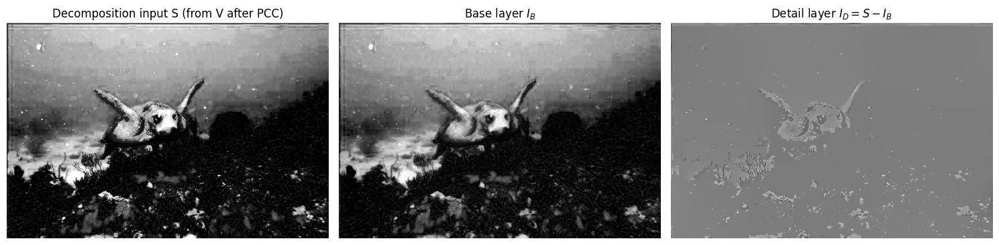

In [ ]:
def decomposition_input(V, use_log=USE_LOG_DOMAIN, eps=LOG_EPS):
    if not use_log:
        return V
    logv = np.log(V + eps)
    span = logv.max() - logv.min()
    return (logv - logv.min()) / span if span > 0 else np.zeros_like(logv)


S_in = decomposition_input(V)
base_layer, detail_layer, admm_history = decompose_v_channel_admm(S_in)

print("Base   range:", float(base_layer.min()),   float(base_layer.max()))
print("Detail range:", float(detail_layer.min()), float(detail_layer.max()))
print("Final primal residual:", admm_history["primal"][-1])
print("Final dual residual  :", admm_history["dual"][-1])

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1); plt.imshow(S_in, cmap="gray", vmin=0, vmax=1); plt.title("Decomposition input S (from V after PCC)"); plt.axis("off")
plt.subplot(1, 3, 2); plt.imshow(base_layer, cmap="gray", vmin=0, vmax=1); plt.title("Base layer $I_B$"); plt.axis("off")
d_lim = float(np.abs(detail_layer).max())
plt.subplot(1, 3, 3); plt.imshow(detail_layer, cmap="gray", vmin=-d_lim, vmax=d_lim); plt.title("Detail layer $I_D = S - I_B$"); plt.axis("off")
plt.tight_layout(); plt.show()

## 8B. Decomposition of the same V channel by the three models



,base min,base max,detail std,detail max|.|,mean |grad base|,mean |grad detail|,mean |base - M1 base|,iterations,final primal,final dual/rho
Model,,,,,,,,,,
M1 L1+L0,-0.01780,0.99397,0.04053,0.51106,0.02103,0.00653,0.00000,20,0.04935,0.04534
M2 L2g+L0,-0.00000,1.00000,0.00000,0.00000,0.02717,0.00000,0.01811,20,0.00000,0.00000
M3 L2g,-0.00005,1.00005,0.00038,0.00535,0.02704,0.00017,0.01802,20,0.00000,0.00000


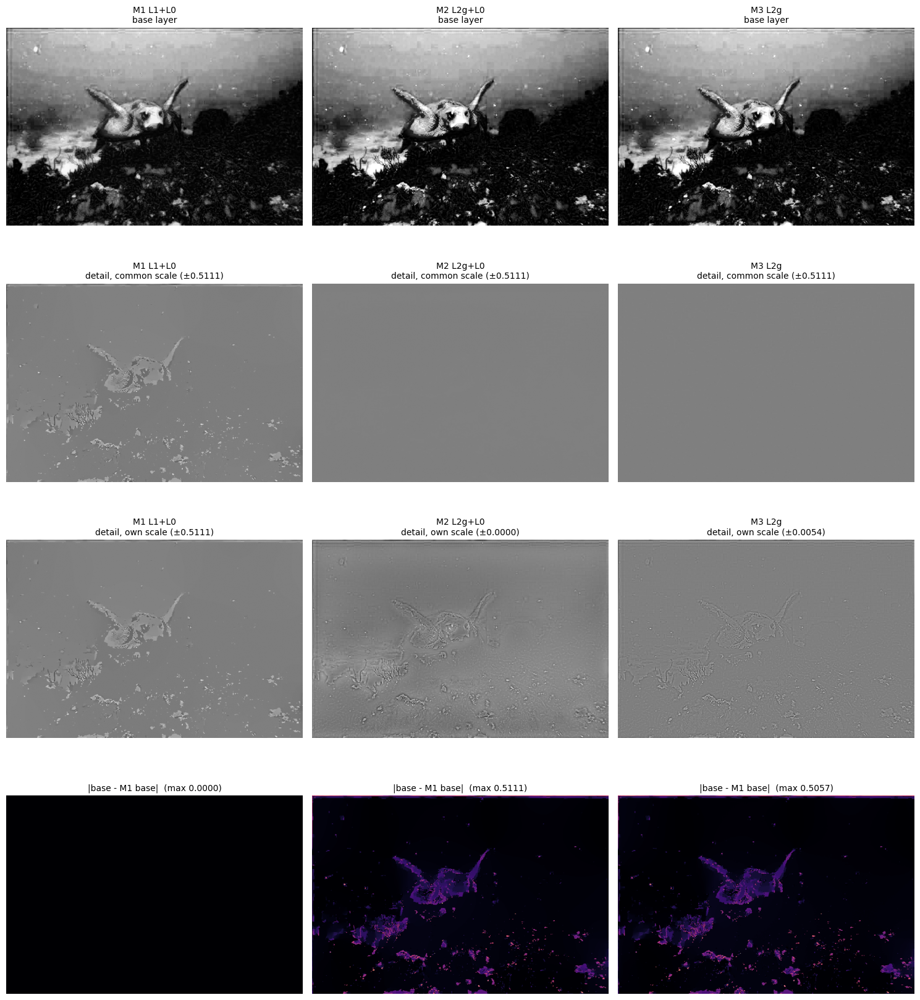

In [ ]:
def _imshow(ax, img, title, cmap=None, vmin=None, vmax=None):
    ax.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=10)
    ax.axis("off")


results_dec = {}
for name in MODEL_NAMES:
    b_, d_, h_ = run_decomposition(name, S_in)
    results_dec[name] = {"base": b_, "detail": d_, "history": h_}

# the paper model run through the common entry point must reproduce the single-model run of Section 8
assert np.allclose(results_dec[MODEL_NAMES[0]]["base"], base_layer), "M1 mismatch with Section 8"

ref_base = results_dec[MODEL_NAMES[0]]["base"]
d_lim_ref = float(np.abs(results_dec[MODEL_NAMES[0]]["detail"]).max())

rows = []
for name in MODEL_NAMES:
    r, hst = results_dec[name], results_dec[name]["history"]
    rows.append({
        "Model": name,
        "base min": r["base"].min(), "base max": r["base"].max(),
        "detail std": r["detail"].std(), "detail max|.|": np.abs(r["detail"]).max(),
        "mean |grad base|": np.abs(gradient(r["base"])).mean(),
        "mean |grad detail|": np.abs(gradient(r["detail"])).mean(),
        "mean |base - M1 base|": np.abs(r["base"] - ref_base).mean(),
        "iterations": len(hst["primal"]),
        "final primal": hst["primal"][-1], "final dual/rho": hst["dual_over_rho"][-1],
    })
table_8b = pd.DataFrame(rows).set_index("Model")
display(table_8b.style.format({c: "{:.5f}" for c in table_8b.columns if c != "iterations"}))

fig, axes = plt.subplots(4, 3, figsize=(15, 17))
for c, name in enumerate(MODEL_NAMES):
    r = results_dec[name]
    own = max(float(np.abs(r["detail"]).max()), 1e-12)
    diff = np.abs(r["base"] - ref_base)
    _imshow(axes[0, c], r["base"], f"{name}\nbase layer", "gray", 0, 1)
    _imshow(axes[1, c], r["detail"], f"{name}\ndetail, common scale (±{d_lim_ref:.4f})", "gray", -d_lim_ref, d_lim_ref)
    _imshow(axes[2, c], r["detail"], f"{name}\ndetail, own scale (±{own:.4f})", "gray", -own, own)
    _imshow(axes[3, c], diff, f"|base - M1 base|  (max {diff.max():.4f})", "magma", 0, max(float(diff.max()), 1e-12))
plt.tight_layout(); plt.show()

## 9. ADMM convergence diagnostics

With the growing penalty ρₖ the primal residual decays by orders of magnitude within the 20 iterations (compare with a constant ρ in Section 17, where it does not). The dual residual is multiplied by ρₖ, so its absolute value grows with the penalty; the plot therefore shows it divided by ρₖ, which is the quantity that measures how much the auxiliary variables are still moving. The update formulas were verified independently: in the convex special case λ₂ = 0 the same updates reproduce a general-purpose convex solver to ~1e-8, and each block update minimizes the Lagrangian of Eq. (6).

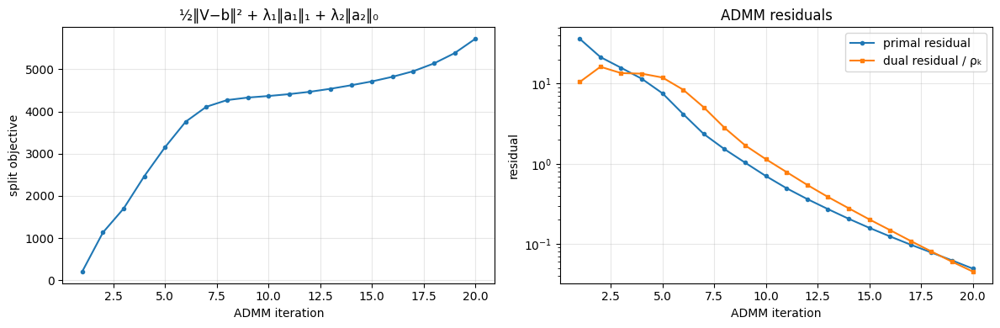

In [ ]:
it = np.arange(1, len(admm_history["objective"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(it, admm_history["objective"], marker="o", ms=3)
plt.xlabel("ADMM iteration"); plt.ylabel("split objective")
plt.title("½‖V−b‖² + λ₁‖a₁‖₁ + λ₂‖a₂‖₀"); plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.semilogy(it, np.maximum(admm_history["primal"], 1e-16), marker="o", ms=3, label="primal residual")
plt.semilogy(it, np.maximum(admm_history["dual_over_rho"], 1e-16), marker="s", ms=3, label="dual residual / ρₖ")
plt.xlabel("ADMM iteration"); plt.ylabel("residual")
plt.title("ADMM residuals"); plt.legend(); plt.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

## 9B. ADMM convergence diagnostics — three models

The residuals are directly comparable (same penalty schedule ρₖ, same units: gradient arrays of the same S). The **objectives are not the same function** (L1 vs global L2 prior, with or without the L0 term), so the objective panel compares the *behaviour* of each curve, not its absolute level.

The two extra panels show the quantities that explain the behaviour of the global-L2 prior:

* **shrink factor α** = 1 − λ₁/(ρₖ‖Q‖₂) applied to the *whole* gradient array (1 → untouched, 0 → whole gradient zeroed);
* **effective Tikhonov weight** μ = λ₁/‖∇B‖₂: at a fixed point of the global-L2 model, B solves (I + μ∇ᵀ∇)B = V − … i.e. the prior behaves like a *linear* smoother whose strength is λ₁ divided by the norm of the whole gradient array (which grows with the image size).

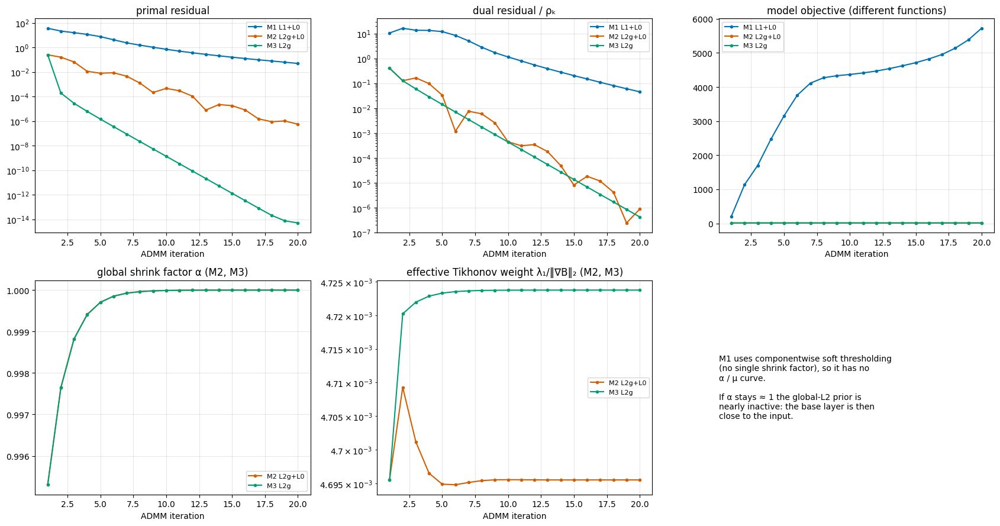

,iterations,final rho,final primal,final dual/rho,final objective,final alpha,final eff. mu
Model,,,,,,,
M1 L1+L0,20,524288,0.0493458,0.0453355,5722.09,nan,nan
M2 L2g+L0,20,524288,5.54903e-07,8.77104e-07,13.3105,1,0.00469555
M3 L2g,20,524288,5.09201e-15,4.23392e-07,13.2537,1,0.00472375


In [ ]:
colors = dict(zip(MODEL_NAMES, MODEL_COLORS))

fig, ax = plt.subplots(2, 3, figsize=(17, 9))
for name in MODEL_NAMES:
    h_ = results_dec[name]["history"]
    it_ = np.arange(1, len(h_["primal"]) + 1)
    kw = dict(marker="o", ms=3, color=colors[name], label=name)
    ax[0, 0].semilogy(it_, np.maximum(h_["primal"], 1e-16), **kw)
    ax[0, 1].semilogy(it_, np.maximum(h_["dual_over_rho"], 1e-16), **kw)
    ax[0, 2].plot(it_, h_["objective"], **kw)
    if "shrink" in h_:
        ax[1, 0].plot(it_, h_["shrink"], **kw)
        ax[1, 1].semilogy(it_, np.maximum(h_["effective_mu"], 1e-16), **kw)

ax[0, 0].set_title("primal residual"); ax[0, 1].set_title("dual residual / ρₖ"); ax[0, 2].set_title("model objective (different functions)")
ax[1, 0].set_title("global shrink factor α (M2, M3)"); ax[1, 1].set_title("effective Tikhonov weight λ₁/‖∇B‖₂ (M2, M3)")
for a in ax.ravel()[:5]:
    a.set_xlabel("ADMM iteration"); a.grid(True, alpha=0.3); a.legend(fontsize=8)
ax[1, 2].axis("off")
ax[1, 2].text(0.0, 0.5, "M1 uses componentwise soft thresholding\n(no single shrink factor), so it has no\nα / μ curve.\n\nIf α stays ≈ 1 the global-L2 prior is\nnearly inactive: the base layer is then\nclose to the input.", fontsize=10, va="center")
plt.tight_layout(); plt.show()

rows = []
for name in MODEL_NAMES:
    h_ = results_dec[name]["history"]
    rows.append({"Model": name, "iterations": len(h_["primal"]), "final rho": h_["rho"][-1],
                 "final primal": h_["primal"][-1], "final dual/rho": h_["dual_over_rho"][-1],
                 "final objective": h_["objective"][-1],
                 "final alpha": h_["shrink"][-1] if "shrink" in h_ else np.nan,
                 "final eff. mu": h_["effective_mu"][-1] if "effective_mu" in h_ else np.nan})
display(pd.DataFrame(rows).set_index("Model").style.format("{:.6g}"))

## 10. Base-layer enhancement — Eq. (7) and gamma

The local mean u<sub>B</sub><sup>K</sup> of each 20×20 block is obtained with an **integral map** (summed-area table), evaluated at every pixel (sliding block). Windows are clipped at the image border and normalized by the number of valid pixels.

  I<sub>B</sub><sup>EK</sup>(i, j) = u<sub>B</sub><sup>K</sup> + δ (I<sub>B</sub>(i, j) − u<sub>B</sub><sup>K</sup>),  δ = 2

Gamma correction is then applied, I<sub>B</sub><sup>E</sup> = (I<sub>B</sub><sup>EK</sup>)<sup>θ</sup>, θ = 0.65. The value is clipped to [0, 1] before the power.

Integral-map local mean self-check passed.


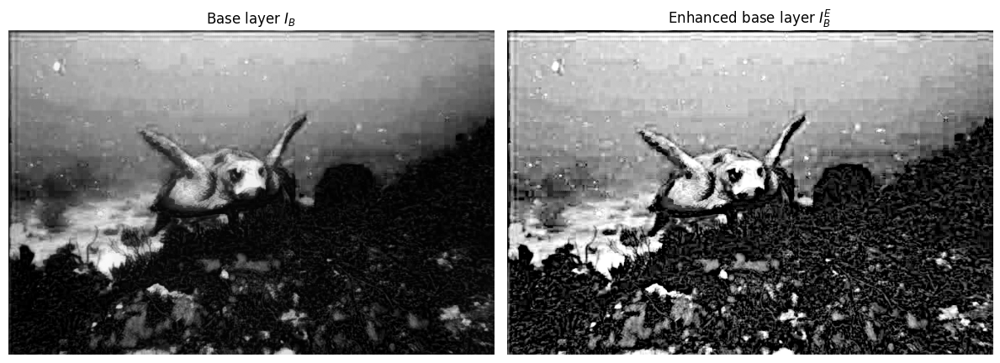

In [ ]:
def local_block_mean(x, block=20):
    # Sliding block x block mean computed with an integral map (summed-area table).
    x = np.asarray(x, dtype=np.float64)
    h, w = x.shape

    integral = np.zeros((h + 1, w + 1), dtype=np.float64)
    integral[1:, 1:] = x.cumsum(axis=0).cumsum(axis=1)

    lo = block // 2
    r0 = np.clip(np.arange(h) - lo, 0, h)
    r1 = np.clip(np.arange(h) - lo + block, 0, h)
    c0 = np.clip(np.arange(w) - lo, 0, w)
    c1 = np.clip(np.arange(w) - lo + block, 0, w)

    total = (integral[r1][:, c1] - integral[r0][:, c1]
             - integral[r1][:, c0] + integral[r0][:, c0])
    count = (r1 - r0)[:, None] * (c1 - c0)[None, :]
    return total / count


def enhance_base_layer(base, block_size=PCDE_BLOCK_SIZE,
                       delta=PCDE_DELTA, theta=PCDE_THETA):
    u = local_block_mean(base, block_size)
    enhanced = u + delta * (base - u)                      # Eq. (7)
    return np.clip(enhanced, 0.0, 1.0) ** theta            # gamma correction


# Self-check of the integral-map mean against a brute-force block mean
_rng = np.random.default_rng(1)
_x = _rng.random((23, 31)); _k = 6
_brute = np.empty_like(_x)
for _i in range(_x.shape[0]):
    for _j in range(_x.shape[1]):
        _win = _x[max(_i - _k // 2, 0):_i - _k // 2 + _k, max(_j - _k // 2, 0):_j - _k // 2 + _k]
        _brute[_i, _j] = _win.mean()
assert np.allclose(local_block_mean(_x, _k), _brute), "integral-map mean mismatch"
print("Integral-map local mean self-check passed.")

enhanced_base = enhance_base_layer(base_layer)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); plt.imshow(base_layer, cmap="gray", vmin=0, vmax=1);     plt.title("Base layer $I_B$");          plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(enhanced_base, cmap="gray", vmin=0, vmax=1);  plt.title("Enhanced base layer $I_B^E$"); plt.axis("off")
plt.tight_layout(); plt.show()

## 10B. Base-layer enhancement — three models

Eq. (7) + gamma (identical code, `enhance_base_layer`) applied to each model's base layer.

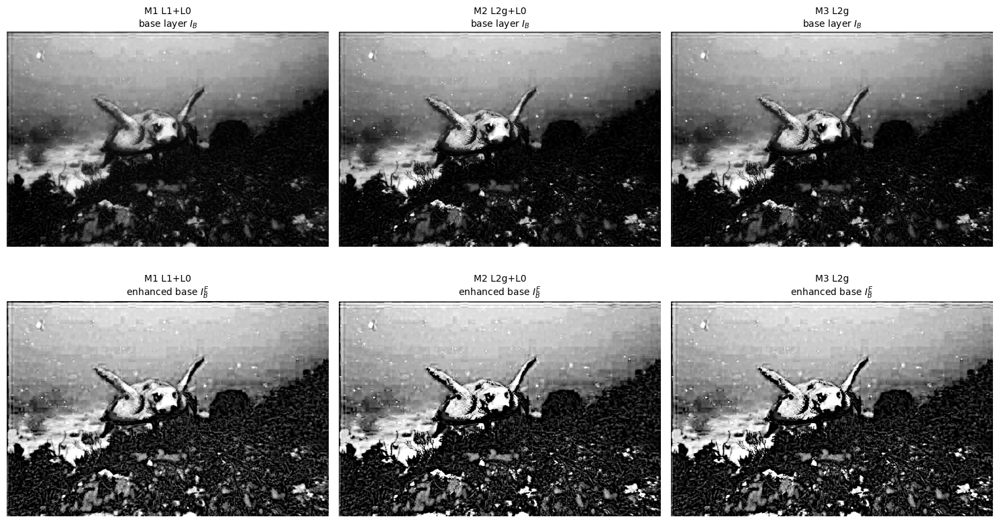

,mean base,mean enhanced,std base,std enhanced,mean |enhanced - base|,mean |enhanced - M1 enhanced|
Model,,,,,,
M1 L1+L0,0.32879,0.42258,0.28158,0.32167,0.10689,0.00000
M2 L2g+L0,0.32879,0.41892,0.29407,0.33631,0.10131,0.02266
M3 L2g,0.32879,0.41890,0.29397,0.33623,0.10134,0.02259


In [ ]:
enh_base = {name: enhance_base_layer(results_dec[name]["base"]) for name in MODEL_NAMES}
assert np.allclose(enh_base[MODEL_NAMES[0]], enhanced_base), "M1 mismatch with Section 10"

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for c, name in enumerate(MODEL_NAMES):
    _imshow(axes[0, c], results_dec[name]["base"], f"{name}\nbase layer $I_B$", "gray", 0, 1)
    _imshow(axes[1, c], enh_base[name], f"{name}\nenhanced base $I_B^E$", "gray", 0, 1)
plt.tight_layout(); plt.show()

rows = []
for name in MODEL_NAMES:
    b_, e_ = results_dec[name]["base"], enh_base[name]
    rows.append({"Model": name, "mean base": b_.mean(), "mean enhanced": e_.mean(),
                 "std base": b_.std(), "std enhanced": e_.std(),
                 "mean |enhanced - base|": np.abs(e_ - b_).mean(),
                 "mean |enhanced - M1 enhanced|": np.abs(e_ - enh_base[MODEL_NAMES[0]]).mean()})
display(pd.DataFrame(rows).set_index("Model").style.format("{:.5f}"))

## 11. Detail-layer enhancement — Eq. (8)

  I<sub>D</sub><sup>E</sup> = sign(I<sub>D</sub>) · ( |I<sub>D</sub>| / max|I<sub>D</sub>| )<sup>σ</sup> · max|I<sub>D</sub>|,  σ = 0.88

The normalization uses the global maximum of |I<sub>D</sub>|.

Detail range before: -0.37224969612852266 0.5110596780090897
Detail range after : -0.38667921095635405 0.5110596780090897


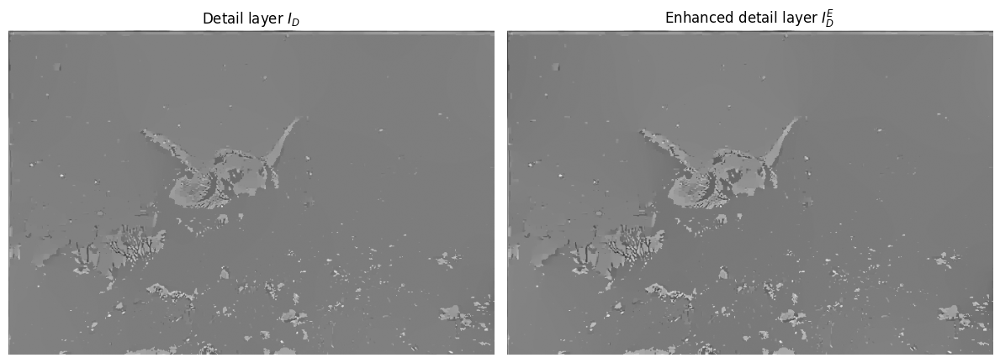

In [ ]:
def enhance_detail_layer(detail, sigma=PCDE_SIGMA):
    max_detail = float(np.max(np.abs(detail)))
    if max_detail <= 1e-12:
        return detail.copy()
    return (np.sign(detail)
            * np.power(np.abs(detail) / max_detail, sigma)
            * max_detail)


enhanced_detail = enhance_detail_layer(detail_layer)

print("Detail range before:", float(detail_layer.min()),   float(detail_layer.max()))
print("Detail range after :", float(enhanced_detail.min()), float(enhanced_detail.max()))

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); plt.imshow(detail_layer,    cmap="gray", vmin=-d_lim, vmax=d_lim); plt.title("Detail layer $I_D$");            plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(enhanced_detail, cmap="gray", vmin=-d_lim, vmax=d_lim); plt.title("Enhanced detail layer $I_D^E$"); plt.axis("off")
plt.tight_layout(); plt.show()

## 11B. Detail-layer enhancement — three models

Eq. (8) (identical code, `enhance_detail_layer`). The normalisation by max|I<sub>D</sub>| makes Eq. (8) scale-invariant in shape, so a model with a very small detail layer keeps a small enhanced detail layer; the three rows below show common scale (of M1) and own scale.

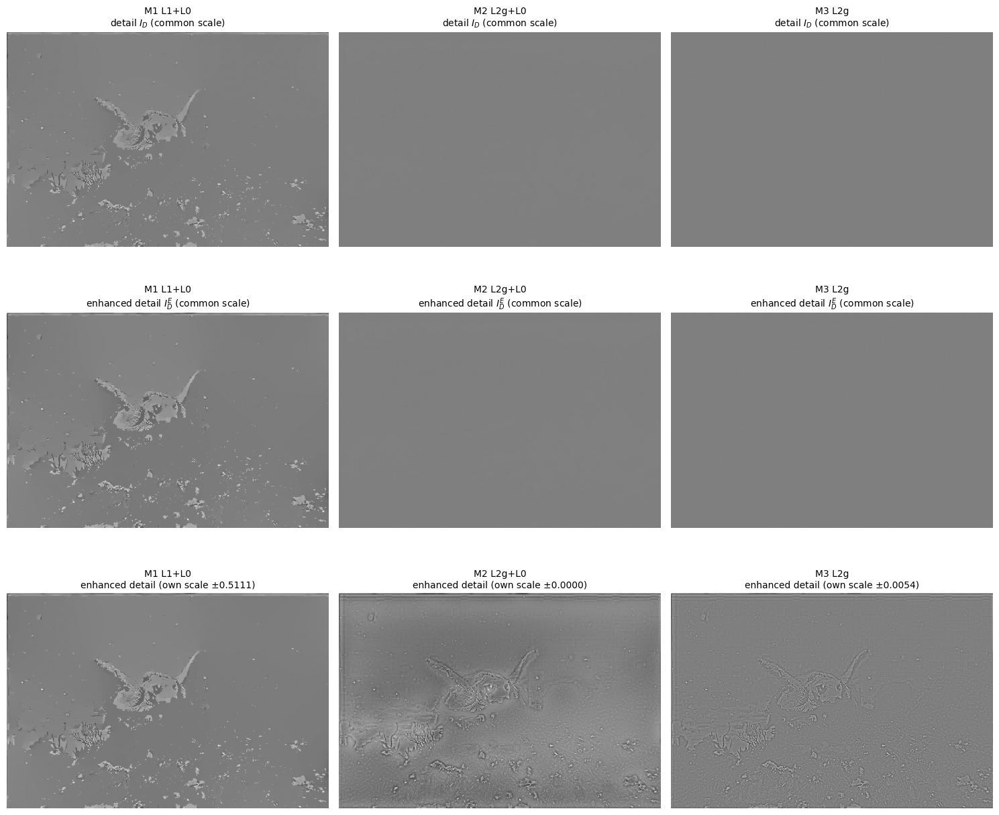

,max|D|,std D,std D^E,std ratio D^E / D,2*std D^E (contribution in Eq. 9)
Model,,,,,
M1 L1+L0,0.51106,0.04053,0.04729,1.16676,0.09457
M2 L2g+L0,0.00000,0.00000,0.00000,1.21871,0.00000
M3 L2g,0.00535,0.00038,0.00046,1.20165,0.00092


In [ ]:
enh_detail = {name: enhance_detail_layer(results_dec[name]["detail"]) for name in MODEL_NAMES}
assert np.allclose(enh_detail[MODEL_NAMES[0]], enhanced_detail), "M1 mismatch with Section 11"

fig, axes = plt.subplots(3, 3, figsize=(15, 13))
for c, name in enumerate(MODEL_NAMES):
    own = max(float(np.abs(enh_detail[name]).max()), 1e-12)
    _imshow(axes[0, c], results_dec[name]["detail"], f"{name}\ndetail $I_D$ (common scale)", "gray", -d_lim_ref, d_lim_ref)
    _imshow(axes[1, c], enh_detail[name], f"{name}\nenhanced detail $I_D^E$ (common scale)", "gray", -d_lim_ref, d_lim_ref)
    _imshow(axes[2, c], enh_detail[name], f"{name}\nenhanced detail (own scale ±{own:.4f})", "gray", -own, own)
plt.tight_layout(); plt.show()

rows = []
for name in MODEL_NAMES:
    d_, e_ = results_dec[name]["detail"], enh_detail[name]
    rows.append({"Model": name, "max|D|": np.abs(d_).max(), "std D": d_.std(), "std D^E": e_.std(),
                 "std ratio D^E / D": e_.std() / max(d_.std(), 1e-12),
                 "2*std D^E (contribution in Eq. 9)": PCDE_DETAIL_GAIN * e_.std()})
display(pd.DataFrame(rows).set_index("Model").style.format("{:.5f}"))

## 12. Reconstruction — Eq. (9)

  I<sub>V</sub><sup>E</sup> = I<sub>B</sub><sup>E</sup> + 2 · I<sub>D</sub><sup>E</sup>

The enhanced V channel is clipped to [0, 1] and combined with the original H and S of the color-corrected image; the result is converted back to RGB.

In [ ]:
V_enhanced = np.clip(enhanced_base + PCDE_DETAIL_GAIN * enhanced_detail, 0.0, 1.0)
final_image = hsv_to_rgb(H, S, V_enhanced)            # float RGB in [0, 255]

print("Enhanced V range:", float(V_enhanced.min()), float(V_enhanced.max()))
print("Final image     :", final_image.shape)

Enhanced V range: 0.0 1.0
Final image     : (453, 678, 3)


## 12B. Reconstruction — three models

V<sup>E</sup> = I<sub>B</sub><sup>E</sup> + 2·I<sub>D</sub><sup>E</sup> (Eq. 9), clipped to [0, 1], combined with the **same** H and S of the colour-corrected image and converted to RGB. The clipped fraction shows how much of the reconstructed V falls outside [0, 1] before clipping.

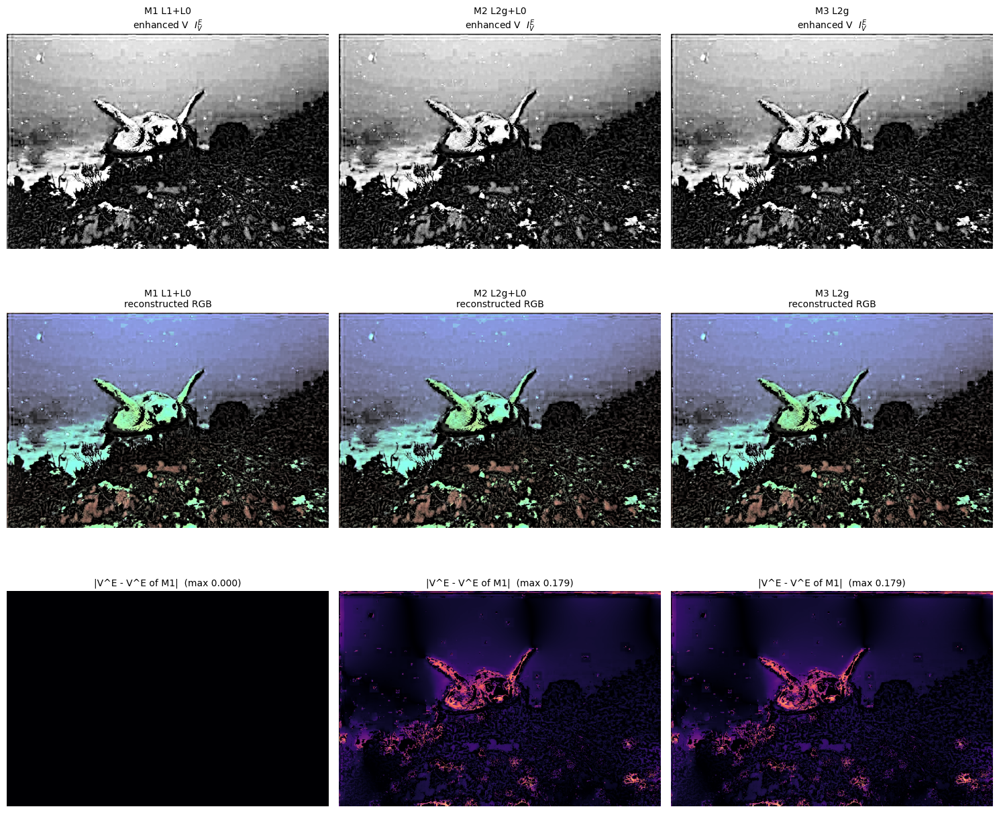

,V^E min (pre-clip),V^E max (pre-clip),mean V^E,std V^E,clipped fraction,mean |V^E - M1 V^E|
Model,,,,,,
M1 L1+L0,-0.68157,1.90884,0.42030,0.33992,0.22425,0.00000
M2 L2g+L0,-0.00000,1.00000,0.41892,0.33631,0.15506,0.01493
M3 L2g,-0.01005,1.01071,0.41898,0.33632,0.23106,0.01489


In [ ]:
V_pre_clip = {name: enh_base[name] + PCDE_DETAIL_GAIN * enh_detail[name] for name in MODEL_NAMES}
V_enh = {name: np.clip(V_pre_clip[name], 0.0, 1.0) for name in MODEL_NAMES}
final_images = {name: hsv_to_rgb(H, S, V_enh[name]) for name in MODEL_NAMES}      # float RGB in [0, 255]
assert np.allclose(final_images[MODEL_NAMES[0]], final_image), "M1 mismatch with Section 12"

fig, axes = plt.subplots(3, 3, figsize=(15, 13))
for c, name in enumerate(MODEL_NAMES):
    diff = np.abs(V_enh[name] - V_enh[MODEL_NAMES[0]])
    _imshow(axes[0, c], V_enh[name], f"{name}\nenhanced V  $I_V^E$", "gray", 0, 1)
    _imshow(axes[1, c], to_uint8(final_images[name]), f"{name}\nreconstructed RGB")
    _imshow(axes[2, c], diff, f"|V^E - V^E of M1|  (max {diff.max():.3f})", "magma", 0, max(float(diff.max()), 1e-12))
plt.tight_layout(); plt.show()

rows = []
for name in MODEL_NAMES:
    v_ = V_pre_clip[name]
    rows.append({"Model": name, "V^E min (pre-clip)": v_.min(), "V^E max (pre-clip)": v_.max(),
                 "mean V^E": V_enh[name].mean(), "std V^E": V_enh[name].std(),
                 "clipped fraction": float(np.mean((v_ < 0) | (v_ > 1))),
                 "mean |V^E - M1 V^E|": np.abs(V_enh[name] - V_enh[MODEL_NAMES[0]]).mean()})
display(pd.DataFrame(rows).set_index("Model").style.format("{:.5f}"))

## 13. Visual result

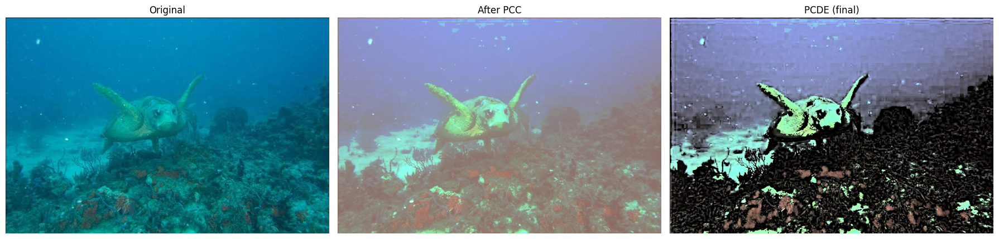

In [ ]:
plt.figure(figsize=(18, 5))
plt.subplot(1, 3, 1); plt.imshow(image);                plt.title("Original");        plt.axis("off")
plt.subplot(1, 3, 2); plt.imshow(to_uint8(pcc_image));  plt.title("After PCC");       plt.axis("off")
plt.subplot(1, 3, 3); plt.imshow(to_uint8(final_image)); plt.title("PCDE (final)");    plt.axis("off")
plt.tight_layout(); plt.show()

## 13B. Visual result — original, PCC and the three models

Second row: the same central crop (middle third of the image in each direction) of every panel.

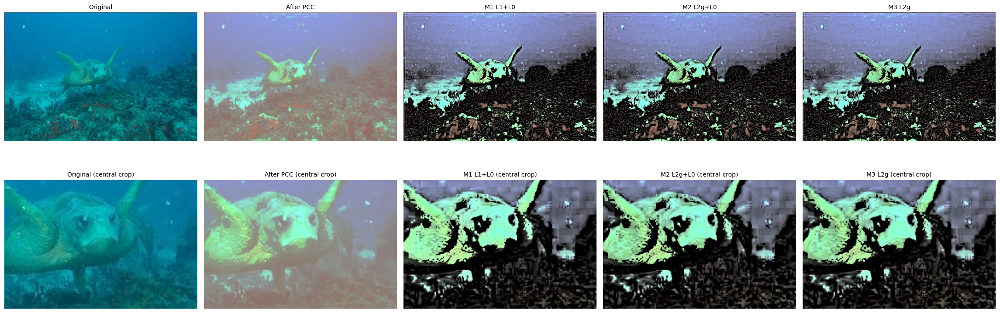

In [ ]:
panels = [("Original", image), ("After PCC", to_uint8(pcc_image))] + [(n, to_uint8(final_images[n])) for n in MODEL_NAMES]
hh, ww = image.shape[:2]
crop = (slice(hh // 3, 2 * hh // 3), slice(ww // 3, 2 * ww // 3))

fig, axes = plt.subplots(2, len(panels), figsize=(4.6 * len(panels), 8.6))
for c, (title, img) in enumerate(panels):
    _imshow(axes[0, c], img, title)
    _imshow(axes[1, c], img[crop], f"{title} (central crop)")
plt.tight_layout(); plt.show()

## 14. Evaluation metrics (paper Sec. III)

The paper evaluates with AG, EI, UIQM, UCIQE and CCF (higher is better). All metrics below are no-reference and take an 8-bit RGB image.

* **AG** (average gradient) and **EI** (edge intensity), as defined in the paper's reference [14]: AG = mean √((Δx² + Δy²)/2) on the gray image; EI = mean Sobel gradient magnitude.
* **UIQM** = 0.0282·UICM + 0.2953·UISM + 3.5753·UIConM (Panetta et al.). UICM uses the 10 %-trimmed mean of RG and YB and the variance over *all* pixels; UISM multiplies the Sobel magnitude (scaled to 255) of each channel by the channel itself and applies EME on 10×10 blocks with weights 0.299 / 0.587 / 0.114; UIConM is the log-AMEE over 10×10 blocks.
* **UCIQE** = 0.4680·σ<sub>C</sub> + 0.2745·con<sub>L</sub> + 0.2576·μ<sub>S</sub> (Yang & Sowmya): σ<sub>C</sub> = std of CIELab chroma, con<sub>L</sub> = top-1 % minus bottom-1 % of luminance, μ<sub>S</sub> = mean of chroma / luminance. Lab is scaled by 1/100 (L in [0, 1]), the scale on which published UCIQE values (≈ 0.3–0.7) live.




In [ ]:
def calculate_ag(rgb):
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(np.float64)
    dx = (gray[:, 1:] - gray[:, :-1])[:-1, :]
    dy = (gray[1:, :] - gray[:-1, :])[:, :-1]
    return float(np.mean(np.sqrt((dx ** 2 + dy ** 2) / 2.0)))


def calculate_ei(rgb):
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(np.float64)
    sx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    return float(np.mean(np.hypot(sx, sy)))


def calculate_uciqe(rgb):
    lab = cv2.cvtColor(rgb.astype(np.float32) / 255.0,
                       cv2.COLOR_RGB2LAB).astype(np.float64) / 100.0
    L, a, b = lab[..., 0], lab[..., 1], lab[..., 2]
    chroma = np.hypot(a, b)
    contrast_l = np.percentile(L, 99) - np.percentile(L, 1)
    saturation = chroma / np.maximum(L, 1e-6)
    return float(0.4680 * chroma.std()
                 + 0.2745 * contrast_l
                 + 0.2576 * saturation.mean())


# ---------------- UIQM ----------------
def _alpha_trimmed_mean(x, alpha=0.1):
    x = np.sort(np.asarray(x, dtype=np.float64).ravel())
    k = x.size
    t_left, t_right = int(np.ceil(alpha * k)), int(np.floor(alpha * k))
    return float(x[t_left:k - t_right].mean())


def calculate_uicm(rgb):
    img = rgb.astype(np.float64)
    R, G, B = img[..., 0], img[..., 1], img[..., 2]
    RG, YB = R - G, (R + G) / 2.0 - B
    mu_rg, mu_yb = _alpha_trimmed_mean(RG), _alpha_trimmed_mean(YB)
    var_rg = np.mean((RG - mu_rg) ** 2)          # variance over all pixels
    var_yb = np.mean((YB - mu_yb) ** 2)
    return float(-0.0268 * np.hypot(mu_rg, mu_yb)
                 + 0.1586 * np.sqrt(var_rg + var_yb))


def _split_blocks(x, w):
    k2, k1 = x.shape[0] // w, x.shape[1] // w
    x = x[:k2 * w, :k1 * w]
    return x.reshape(k2, w, k1, w, *x.shape[2:]), k1 * k2


def _eme(x, w=10):
    blocks, n = _split_blocks(x, w)
    hi, lo = blocks.max(axis=(1, 3)), blocks.min(axis=(1, 3))
    ok = (lo > 0) & (hi > 0)
    return float(2.0 / n * np.log(hi[ok] / lo[ok]).sum())


def _sobel_magnitude(channel):
    gx = ndimage.sobel(channel, axis=0)
    gy = ndimage.sobel(channel, axis=1)
    mag = np.hypot(gx, gy)
    peak = mag.max()
    return mag * (255.0 / peak) if peak > 0 else mag


def calculate_uism(rgb):
    img = rgb.astype(np.float64)
    weights = (0.299, 0.587, 0.114)
    return float(sum(
        wc * _eme(_sobel_magnitude(img[..., c]) * img[..., c], 10)
        for c, wc in enumerate(weights)))


def calculate_uiconm(rgb, window=10):
    blocks, n = _split_blocks(rgb.astype(np.float64), window)
    hi, lo = blocks.max(axis=(1, 3, 4)), blocks.min(axis=(1, 3, 4))
    top, bottom = hi - lo, hi + lo
    ok = (top > 0) & (bottom > 0)
    ratio = top[ok] / bottom[ok]
    return float(-(ratio * np.log(ratio)).sum() / n)


def calculate_uiqm(rgb):
    return float(0.0282 * calculate_uicm(rgb)
                 + 0.2953 * calculate_uism(rgb)
                 + 3.5753 * calculate_uiconm(rgb))


def evaluate_image(rgb_u8):
    return {"AG": calculate_ag(rgb_u8),
            "EI": calculate_ei(rgb_u8),
            "UIQM": calculate_uiqm(rgb_u8),
            "UCIQE": calculate_uciqe(rgb_u8)}

## 15. Evaluate: original, PCC and PCDE

In [ ]:
evaluation_images = {
    "Original": image,
    "PCC only": to_uint8(pcc_image),
    "PCDE (full)": to_uint8(final_image),
}

results = pd.DataFrame(
    [{"Image": name, **evaluate_image(img)} for name, img in evaluation_images.items()]
)

display(results.style.format({m: "{:.4f}" for m in ["AG", "EI", "UIQM", "UCIQE"]}))

,Image,AG,EI,UIQM,UCIQE
0,Original,3.2096,24.9235,0.8887,0.3146
1,PCC only,2.6366,20.6827,2.0871,0.2332
2,PCDE (full),13.5081,107.5646,1.1629,0.3979


## 15B. Evaluation — original, PCC and the three models

Same metrics and code as Section 14. The best value among the **three models** is highlighted in each metric column. As noted in Section 14, a single-image score is only meaningful relative to the other rows of the same table.

,AG,EI,UIQM,UCIQE,mean intensity
Image,,,,,
Original,3.2096,24.9235,0.8887,0.3146,87.1926
PCC only,2.6366,20.6827,2.0871,0.2332,149.0245
M1 L1+L0,13.5081,107.5646,1.1629,0.3979,89.3297
M2 L2g+L0,13.6385,108.9873,1.1001,0.3932,89.0486
M3 L2g,13.6473,109.0476,1.1010,0.3933,89.0615


,AG,EI,UIQM,UCIQE
M2 L2g+L0 vs M1 [%],+0.97,+1.32,-5.40,-1.18
M3 L2g vs M1 [%],+1.03,+1.38,-5.32,-1.17


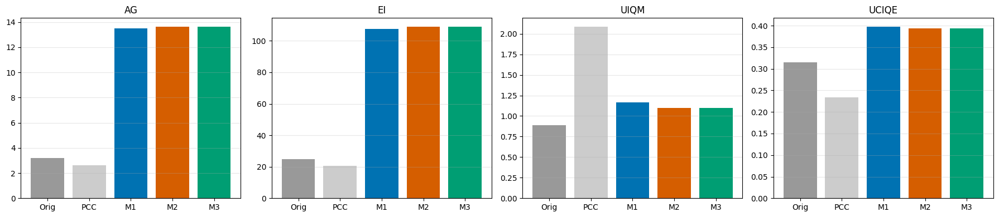

In [ ]:
metric_names = ["AG", "EI", "UIQM", "UCIQE"]
eval_images = {"Original": image, "PCC only": to_uint8(pcc_image)}
eval_images.update({name: to_uint8(final_images[name]) for name in MODEL_NAMES})

results3 = pd.DataFrame([{"Image": n, **evaluate_image(img), "mean intensity": float(img.mean())}
                         for n, img in eval_images.items()]).set_index("Image")

display(results3.style
        .format("{:.4f}")
        .highlight_max(axis=0, subset=pd.IndexSlice[MODEL_NAMES, metric_names], color="#cfe8cf"))

# relative change of M2 and M3 with respect to the paper model M1
rel = (results3.loc[MODEL_NAMES[1:], metric_names].values / results3.loc[MODEL_NAMES[0], metric_names].values - 1.0) * 100.0
display(pd.DataFrame(rel, index=[f"{n} vs M1 [%]" for n in MODEL_NAMES[1:]], columns=metric_names).style.format("{:+.2f}"))

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
bar_colors = ["#999999", "#cccccc"] + list(MODEL_COLORS)
for a, m in zip(axes, metric_names):
    a.bar(range(len(results3)), results3[m].values, color=bar_colors)
    a.set_xticks(range(len(results3)))
    a.set_xticklabels(["Orig", "PCC", "M1", "M2", "M3"])
    a.set_title(m); a.grid(True, axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

## 16. Ablation study (paper Sec. III-C, Fig. 5, Table II)

Three variants are compared with the full model:

* **w/o PCC** — the raw image enters the dual-prior stage directly.
* **w/o BLE** — base layer is not enhanced: I<sub>B</sub><sup>E</sup> = I<sub>B</sub> (no Eq. (7), no gamma).
* **w/o DLE** — detail layer is not enhanced: I<sub>D</sub><sup>E</sup> = I<sub>D</sub> and it is added with weight 1 (no Eq. (8), no factor 2).

The paper does not spell out the exact construction of the ablated models; the definitions above are the natural reading of the three module names.

,Ablated model,AG,EI,UIQM,UCIQE
0,w/o PCC,4.6868,35.4950,0.8634,0.2878
1,w/o BLE,8.0739,62.9531,0.9088,0.3909
2,w/o DLE,12.9560,105.0271,1.1857,0.3954
3,PCDE (full),13.5081,107.5646,1.1629,0.3979


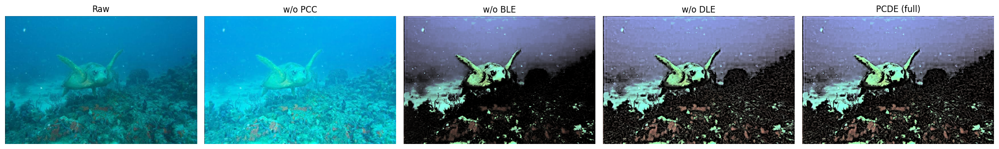

In [ ]:
def dual_prior_contrast_enhancement(rgb_255, growth=ADMM_RHO_GROWTH, use_log=USE_LOG_DOMAIN,
                                    enhance_base=True, enhance_detail=True):
    h, s, v = rgb_to_hsv(rgb_255)
    base, detail, history = decompose_v_channel_admm(
        decomposition_input(v, use_log=use_log), growth=growth)

    base_e = enhance_base_layer(base) if enhance_base else base
    if enhance_detail:
        detail_e, gain = enhance_detail_layer(detail), PCDE_DETAIL_GAIN
    else:
        detail_e, gain = detail, 1.0

    v_e = np.clip(base_e + gain * detail_e, 0.0, 1.0)
    info = {"history": history, "detail_std": float(detail.std())}
    return hsv_to_rgb(h, s, v_e), info


raw_float = image.astype(np.float64)

ablation_outputs = {
    "w/o PCC":     dual_prior_contrast_enhancement(raw_float)[0],
    "w/o BLE":     dual_prior_contrast_enhancement(pcc_image, enhance_base=False)[0],
    "w/o DLE":     dual_prior_contrast_enhancement(pcc_image, enhance_detail=False)[0],
    "PCDE (full)": dual_prior_contrast_enhancement(pcc_image)[0],
}

# the step-by-step result above and the packaged function must agree
assert np.allclose(ablation_outputs["PCDE (full)"], final_image), "pipeline mismatch"

ablation_table = pd.DataFrame(
    [{"Ablated model": name, **evaluate_image(to_uint8(img))}
     for name, img in ablation_outputs.items()]
)
display(ablation_table.style.format({m: "{:.4f}" for m in ["AG", "EI", "UIQM", "UCIQE"]}))

plt.figure(figsize=(20, 4.5))
panels = [("Raw", image)] + [(k, to_uint8(v)) for k, v in ablation_outputs.items()]
for idx, (title, img) in enumerate(panels, 1):
    plt.subplot(1, len(panels), idx); plt.imshow(img); plt.title(title); plt.axis("off")
plt.tight_layout(); plt.show()

## 16B. Ablation study for the three models

Same three ablations as Section 16 (w/o PCC, w/o BLE, w/o DLE) plus the full model, now run for each decomposition model through `dual_prior_contrast_enhancement_model` (the original `dual_prior_contrast_enhancement` is untouched; the M1 results are asserted to be identical to it).

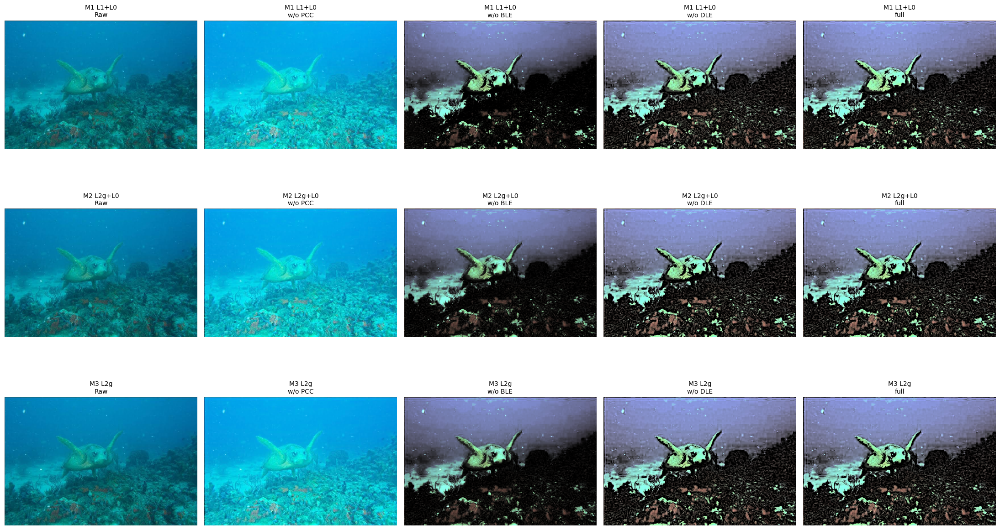

In [ ]:
def dual_prior_contrast_enhancement_model(model, rgb_255, enhance_base=True, enhance_detail=True, **decomp_kwargs):
    # Same pipeline as dual_prior_contrast_enhancement(), for any of the three decomposition models
    use_log = decomp_kwargs.pop("use_log", USE_LOG_DOMAIN)
    h, s, v = rgb_to_hsv(rgb_255)
    base, detail, history = run_decomposition(model, decomposition_input(v, use_log=use_log), **decomp_kwargs)

    base_e = enhance_base_layer(base) if enhance_base else base
    if enhance_detail:
        detail_e, gain = enhance_detail_layer(detail), PCDE_DETAIL_GAIN
    else:
        detail_e, gain = detail, 1.0

    v_e = np.clip(base_e + gain * detail_e, 0.0, 1.0)
    info = {"history": history, "detail_std": float(detail.std())}
    return hsv_to_rgb(h, s, v_e), info


ablation_all = {}
for name in MODEL_NAMES:
    ablation_all[name] = {
        "w/o PCC": dual_prior_contrast_enhancement_model(name, raw_float)[0],
        "w/o BLE": dual_prior_contrast_enhancement_model(name, pcc_image, enhance_base=False)[0],
        "w/o DLE": dual_prior_contrast_enhancement_model(name, pcc_image, enhance_detail=False)[0],
        "full":    dual_prior_contrast_enhancement_model(name, pcc_image)[0],
    }

# M1 through the generalised function must equal the original ablation of Section 16
for k_new, k_old in [("w/o PCC", "w/o PCC"), ("w/o BLE", "w/o BLE"), ("w/o DLE", "w/o DLE"), ("full", "PCDE (full)")]:
    assert np.allclose(ablation_all[MODEL_NAMES[0]][k_new], ablation_outputs[k_old]), f"M1 ablation mismatch: {k_new}"

rows = []
for name in MODEL_NAMES:
    for variant, img in ablation_all[name].items():
        rows.append({"Model": name, "Variant": variant, **evaluate_image(to_uint8(img))})
ablation_table_all = pd.DataFrame(rows).set_index(["Model", "Variant"])
display(ablation_table_all.style.format("{:.4f}"))

# metric drop (full - ablated) per model: positive = the module helps
drop = []
for name in MODEL_NAMES:
    full = ablation_table_all.loc[(name, "full")]
    for variant in ("w/o PCC", "w/o BLE", "w/o DLE"):
        drop.append({"Model": name, "Variant": variant, **(full - ablation_table_all.loc[(name, variant)]).to_dict()})
display(pd.DataFrame(drop).set_index(["Model", "Variant"]).style.format("{:+.4f}").set_caption("full model minus ablated model (positive = module improves the metric)"))

variants_order = ["w/o PCC", "w/o BLE", "w/o DLE", "full"]
fig, axes = plt.subplots(len(MODEL_NAMES), 5, figsize=(22, 4.4 * len(MODEL_NAMES)))
for r_, name in enumerate(MODEL_NAMES):
    _imshow(axes[r_, 0], image, f"{name}\nRaw")
    for c_, v_name in enumerate(variants_order, 1):
        _imshow(axes[r_, c_], to_uint8(ablation_all[name][v_name]), f"{name}\n{v_name}")
plt.tight_layout(); plt.show()

## 17. Sensitivity to the ADMM details not given in the PCDE paper

Two details decide the outcome and are taken from [35]: the **log-domain input** and the **growing penalty**. The table compares them with the alternatives (this is a check of the implementation choices, not part of the published method, and can be skipped). Reading it:

* **constant ρ** (growth 1): the primal residual stays large, i.e. the 20 iterations are *not* converged and the result is an arbitrary early-stopped iterate;
* **growing ρ** (growth 2 or 4): the residual decays and the result is stable; growth 2 and 4 give practically the same image;
* **plain V instead of log-V**: a markedly different (much brighter, hazier) result, because the same λ's act on a different intensity distribution.

In [ ]:
variants = [
    ("log-V, growth 2 (default)", dict(use_log=True,  growth=2.0)),
    ("log-V, growth 4 ([35] code)", dict(use_log=True,  growth=4.0)),
    ("log-V, constant rho",        dict(use_log=True,  growth=1.0)),
    ("plain V, growth 2",          dict(use_log=False, growth=2.0)),
    ("plain V, constant rho",      dict(use_log=False, growth=1.0)),
]

rows = []
for name, kwargs in variants:
    out, info = dual_prior_contrast_enhancement(pcc_image, **kwargs)
    rows.append({"variant": name,
                 "final primal residual": info["history"]["primal"][-1],
                 "std of detail layer": info["detail_std"],
                 "mean intensity": float(out.mean()),
                 **evaluate_image(to_uint8(out))})

display(pd.DataFrame(rows).style.format(
    {"final primal residual": "{:.4f}", "std of detail layer": "{:.5f}",
     "mean intensity": "{:.1f}", **{m: "{:.4f}" for m in ["AG", "EI", "UIQM", "UCIQE"]}}))

,variant,final primal residual,std of detail layer,mean intensity,AG,EI,UIQM,UCIQE
0,"log-V, growth 2 (default)",0.0493,0.04053,89.3,13.5081,107.5646,1.1629,0.3979
1,"log-V, growth 4 ([35] code)",0.0000,0.04041,89.9,13.8133,110.0520,1.1546,0.3973
2,"log-V, constant rho",50.5821,0.05891,90.1,14.8984,115.6831,1.4544,0.4000
3,"plain V, growth 2",0.0267,0.01649,169.8,4.0751,31.1293,2.3989,0.2288
4,"plain V, constant rho",33.7705,0.03070,169.4,5.9667,44.3947,2.8570,0.2386


## 17B. Sensitivity of the global-L2 models (M2, M3)

The paper's λ₁ = 0.25 was chosen for the **L1** prior, whose soft threshold λ₁/ρ acts on every gradient entry. In the global-L2 models the threshold λ₁/ρ is compared with the norm of the **entire** gradient array, which is far larger, so for the same λ₁ the shrink factor α stays close to 1 and the prior is almost inactive. This section shows

* a **λ₁ sweep** (growing ρ, 20 iterations, as in the rest of the notebook) — final α, effective weight λ₁/‖∇B‖₂, size of the detail layer and the metrics;
* **converged references** with a *constant* penalty (`growth = 1`, `REFERENCE_ITERATIONS` iterations). For M3 (convex) this is the true minimiser of its objective; for M2 (non-convex) it is the iterate reached by constant-penalty ADMM. Increase `REFERENCE_ITERATIONS` for a tighter reference (it costs one FFT solve per iteration).

This is a check of how the extra models behave, not part of the published method.

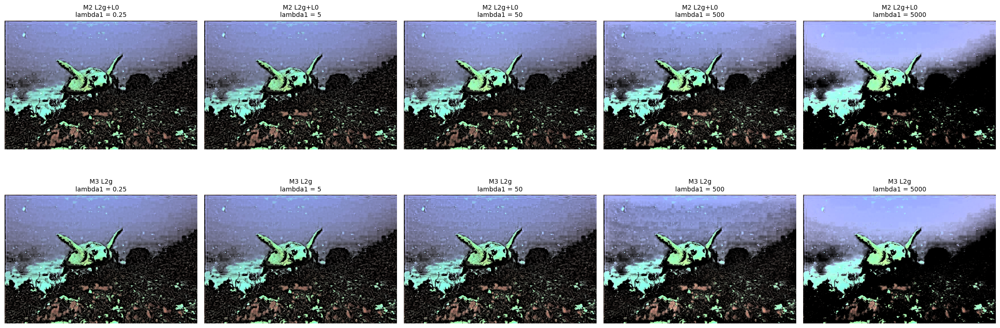

In [ ]:
SWEEP_LAMBDA1 = [0.25, 5.0, 50.0, 500.0, 5000.0]
REFERENCE_ITERATIONS = 100
REFERENCE_LAMBDA1 = [L2G_LAMBDA1, 50.0]

new_models = MODEL_NAMES[1:]
rows, sweep_imgs = [], {n: [] for n in new_models}


def _row(name, label, out, info):
    hh_ = info["history"]
    return {"model": name, "variant": label,
            "final primal": hh_["primal"][-1], "final alpha": hh_["shrink"][-1],
            "eff. mu": hh_["effective_mu"][-1], "std of detail": info["detail_std"],
            "mean intensity": float(out.mean()), **evaluate_image(to_uint8(out))}


for name in new_models:
    for lam in SWEEP_LAMBDA1:
        out, info = dual_prior_contrast_enhancement_model(name, pcc_image, lambda1=lam)
        rows.append(_row(name, f"lambda1={lam:g}, growing rho", out, info))
        sweep_imgs[name].append((lam, out))
    for lam in REFERENCE_LAMBDA1:
        out, info = dual_prior_contrast_enhancement_model(name, pcc_image, lambda1=lam, growth=1.0,
                                                          iterations=REFERENCE_ITERATIONS)
        rows.append(_row(name, f"lambda1={lam:g}, constant rho, {REFERENCE_ITERATIONS} it", out, info))

display(pd.DataFrame(rows).set_index(["model", "variant"]).style.format(
    {"final primal": "{:.4f}", "final alpha": "{:.6f}", "eff. mu": "{:.3e}", "std of detail": "{:.5f}",
     "mean intensity": "{:.1f}", **{m: "{:.4f}" for m in ["AG", "EI", "UIQM", "UCIQE"]}}))

fig, axes = plt.subplots(len(new_models), len(SWEEP_LAMBDA1), figsize=(4.4 * len(SWEEP_LAMBDA1), 4.2 * len(new_models)))
for r_, name in enumerate(new_models):
    for c_, (lam, out) in enumerate(sweep_imgs[name]):
        _imshow(axes[r_, c_], to_uint8(out), f"{name}\nlambda1 = {lam:g}")
plt.tight_layout(); plt.show()

## 18B. Notes on the added models

1. **What changes between the models.** M1 → M2 replaces only the A₁ update (componentwise soft threshold → one global shrink factor, Eq. 20). The B update (2η), the A₂ hard threshold, the multiplier updates and the residual formulas of M2 are those of M1. M3 additionally drops the L0 block: one constraint, one multiplier, B update with coefficient η instead of 2η, and D = V − B is not constrained by any prior.


2. **Initialisation.** M2/M3 use A₁⁰ = ∇V as in the derivations; M1 keeps its A⁰ = 0 from the released code of [35]. `L2G_INIT_A1_FROM_GRADIENT = False` makes M2/M3 start from A₁⁰ = 0 as well.
3. **Convexity.** M3 is convex (global optimum of ADMM with constant η, verified in 7D). M1 and M2 contain the L0 term and are non-convex: small residuals indicate stabilisation, not global optimality.
4. **Everything else is shared**, so differences between the three result images come only from the decomposition stage; the assertions in 8B–16B check that the generalised code reproduces the original M1 results exactly.